# Chapter 8: Document & multimodal processing

Companion notebook for [ch08/README.md](../README.md). Every number in the chapter comes from the
saved outputs below.

Prerequisites: `.env` configured and the ShopFlow database running (last section). The local-model
results (gemma3:4b, glm-ocr on Ollama) are loaded from saved runs; nothing in this notebook needs
Ollama.

The bulk evals were run once from the terminal (`eval/run_eval.py`, `eval/run_pipeline.py`) and
saved to `eval/results/`, so re-running this notebook re-scores them for free. Cells marked
**live** call a model every time they run (about $0.05 in total).

In [1]:
import os
import shutil
import subprocess
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import openai
import pandas as pd
import PIL
import pypdf
import reportlab
from PIL import Image

sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd() / "eval"))
from ch08_eval import judge, load_run, summarize
from ch08_extract import (
    JSON_OBJECT_FORMAT, NAIVE_PROMPT, extract_from_image, extract_from_text, pdf_text,
)
from ch08_invoice import SCORE_FIELDS, score_invoice
from ch08_pipeline import ModelSpec, process_file, record, setup_tables
from llmprod import chat_client, connect, get_settings
from make_invoices import load_truth, write_dataset
from run_pipeline import load_outcomes
from show_mistakes import mistakes

settings = get_settings()
DATA, RESULTS, IMAGES = Path("data"), Path("eval/results"), Path("../images")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 70)
print("run date:", date.today(), "| model:", settings.llm_model, "| strong:", settings.llm_model_strong)
print(f"openai {openai.__version__} | pypdf {pypdf.__version__} | reportlab {reportlab.Version} "
      f"| pillow {PIL.__version__}")

run date: 2026-11-09 | model: openai/gpt-6-luna | strong: anthropic/claude-sonnet-5.5
openai 3.46.0 | pypdf 7.0.0 | reportlab 5.1.0 | pillow 13.0.0


### Local models (optional)

`RUN_LOCAL=1` re-runs the local-model evals on Ollama before the analysis (about 20 minutes on a
free RTX 3090). Default off: the cells below then use whatever saved runs exist in
`eval/results/`.

In [2]:
RUN_LOCAL = os.environ.get("RUN_LOCAL") == "1"
LOCAL_RUNS = ["text-v1-qwen3-8b", "text-printed-qwen3-8b", "scan-vision-qwen2.5vl-7b",
              "scan-printed-qwen2.5vl-7b", "scan-ocr-glm-qwen3-8b"]
if RUN_LOCAL:
    for cmd in [*(["eval/run_eval.py", n] for n in LOCAL_RUNS),
                ["eval/run_pipeline.py", "local-first-printed", "--files", "scans"]]:
        out = subprocess.run([sys.executable, *cmd], capture_output=True, text=True, check=True)
        print(out.stdout.strip().splitlines()[-1])
print("RUN_LOCAL:", RUN_LOCAL, "| local runs on disk:",
      [n for n in LOCAL_RUNS if (RESULTS / f"{n}.json").exists()])

text-v1-qwen3-8b: all_correct=78.0% parse_fail=0.0% caught=11 silent_wrong=0 p50=4.1s cost=$0.0000 wall=128s -> eval/results/text-v1-qwen3-8b.json


text-printed-qwen3-8b: all_correct=42.0% parse_fail=50.0% caught=26 silent_wrong=3 p50=4.2s cost=$0.0000 wall=130s -> eval/results/text-printed-qwen3-8b.json


scan-vision-qwen2.5vl-7b: all_correct=10.0% parse_fail=0.0% caught=9 silent_wrong=0 p50=9.2s cost=$0.0000 wall=53s -> eval/results/scan-vision-qwen2.5vl-7b.json


scan-printed-qwen2.5vl-7b: all_correct=50.0% parse_fail=50.0% caught=5 silent_wrong=0 p50=7.0s cost=$0.0000 wall=67s -> eval/results/scan-printed-qwen2.5vl-7b.json


scan-ocr-glm-qwen3-8b: all_correct=20.0% parse_fail=0.0% caught=8 silent_wrong=0 p50=5.6s cost=$0.0000 wall=23s -> eval/results/scan-ocr-glm-qwen3-8b.json


saved eval/results/pipeline-local-first-printed-scans.json
RUN_LOCAL: True | local runs on disk: ['text-v1-qwen3-8b', 'text-printed-qwen3-8b', 'scan-vision-qwen2.5vl-7b', 'scan-printed-qwen2.5vl-7b', 'scan-ocr-glm-qwen3-8b']


## The data

50 supplier invoices as PDFs in three layouts, plus 10 "scans": PNG renderings of 10 of those
invoices, rotated, blurred and noised like a photocopy. `ground_truth.json` holds the right
answer for every file. The generator is deterministic (same seed, byte-identical files).

In [3]:
truth_meta = write_dataset(DATA, seed=8)["files"]
TRUTH = {name: inv for name, (_, inv) in load_truth(DATA).items()}
df = pd.DataFrame([{"file": k, "kind": v["kind"], "layout": v["layout"], "tier": v.get("tier"),
                    "lines": len(v["invoice"]["line_items"]),
                    "pages": len(pypdf.PdfReader(DATA / "pdf" / k).pages) if v["kind"] == "pdf" else 1}
                   for k, v in truth_meta.items()])
print(df.groupby(["kind", "layout"]).agg(files=("file", "count"), min_lines=("lines", "min"),
                                         max_lines=("lines", "max"), max_pages=("pages", "max")))
print("\nscan tiers:", df[df.kind == "scan"].tier.value_counts().to_dict())

             files  min_lines  max_lines  max_pages
kind layout                                        
pdf  A          17          2          9          1
     B          17          2         42          2
     C          16          2         38          2
scan A           1          9          9          1
     B           6          3          9          1
     C           3          3          7          1

scan tiers: {'mild': 6, 'hard': 4}


saved ../images/08-samples.png | first file per layout: {'A': 'inv-006.pdf', 'B': 'inv-001.pdf', 'C': 'inv-004.pdf'}


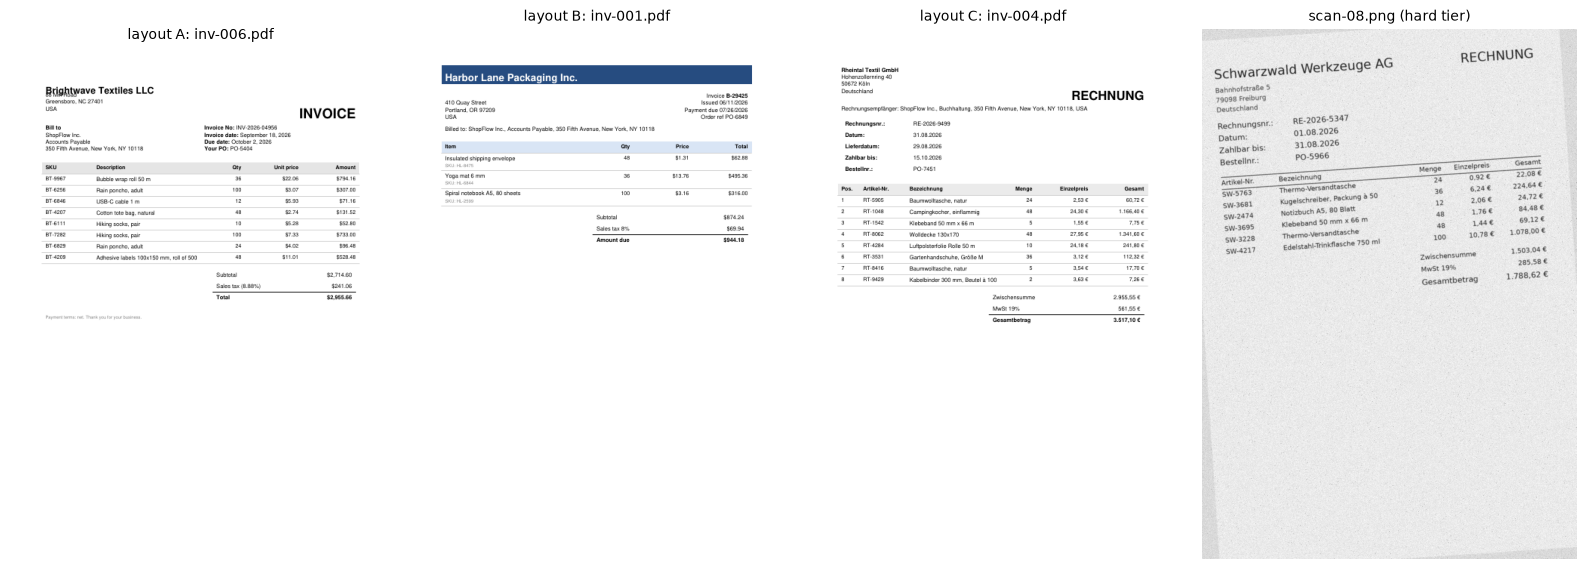

In [4]:
# One page per layout, plus a 'hard' scan.
def thumb_pdf(name: str, dpi: int = 60) -> Image.Image:
    out = Path("/tmp") / name.replace(".pdf", "")
    subprocess.run(["pdftoppm", "-r", str(dpi), "-png", "-f", "1", "-l", "1", "-singlefile",
                    str(DATA / "pdf" / name), str(out)], check=True, capture_output=True)
    return Image.open(f"{out}.png")

first_of = {lay: min(k for k, v in truth_meta.items() if v["kind"] == "pdf" and v["layout"] == lay)
            for lay in "ABC"}
panels = []
if shutil.which("pdftoppm"):  # poppler-utils, only used for this picture
    panels = [(f"layout {lay}: {f}", thumb_pdf(f)) for lay, f in first_of.items()]
panels.append(("scan-08.png (hard tier)", Image.open(DATA / "scans" / "scan-08.png")))
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 5.6))
for ax, (title, im) in zip(axes, panels):
    ax.imshow(im, cmap="gray"); ax.set_title(title, fontsize=10); ax.axis("off")
fig.tight_layout(); fig.savefig(IMAGES / "08-samples.png", dpi=110, facecolor="white")
print("saved", IMAGES / "08-samples.png", "| first file per layout:", first_of)

### What pypdf gives us

The text layer of a UK invoice. `Issued 10/01/2026` is 10 January (British supplier), and the
due date is printed right below it.

In [5]:
t0 = time.perf_counter()
texts = {p.name: pdf_text(p) for p in sorted((DATA / "pdf").glob("*.pdf"))}
dt = time.perf_counter() - t0
print(f"pypdf: {len(texts)} PDFs in {dt * 1000:.0f} ms ({dt / len(texts) * 1000:.1f} ms each)\n")
text = texts["inv-003.pdf"]
print(text[:520])
print("...\n", len(text), "characters; truth date:", TRUTH["inv-003.pdf"].date)

pypdf: 50 PDFs in 210 ms (4.2 ms each)

Pennine Cycle Parts Ltd
Unit 3, Don Works
Sheffield S4 7YA
United Kingdom
 Invoice T-63366
 Issued 10/01/2026
 Payment due 24/01/2026
 Order ref PO-6583
Billed to: ShopFlow Inc., Accounts Payable, 350 Fifth Avenue, New York, NY 10118
Item
Qty
Price
Total
Adhesive labels 100x150 mm, roll of 500
SKU: PC-2313
2
£8.55
£17.10
Bamboo cutting board
SKU: PC-2558
1
£8.67
£8.67
Glass storage jar 1 L
SKU: PC-2745
100
£5.09
£509.00
Camping stove, single burner
SKU: PC-3517
100
£30.99
£3,099.00
Bamboo cutting board
SKU: PC-3433
...
 592 characters; truth date: 2026-01-10


## v0: the naive extraction (live)

One prompt that lists the keys, JSON mode, no schema, no rules.

In [6]:
client = chat_client(timeout=180)
LUNA = settings.llm_model
ex = extract_from_text(client, LUNA, text, system=NAIVE_PROMPT, response_format=JSON_OBJECT_FORMAT)
print(ex.raw[:420], "...")
print(f"\n{ex.prompt_tokens} in / {ex.completion_tokens} out tokens, ${ex.cost_usd:.6f}, {ex.latency_s:.1f} s")
print("all fields correct:", judge("inv-003.pdf", ex, TRUTH["inv-003.pdf"]).correct)

{
  "supplier": "Pennine Cycle Parts Ltd",
  "invoice_no": "T-63366",
  "date": "2026-01-10",
  "currency": "GBP",
  "line_items": [
    {
      "sku": "PC-2313",
      "desc": "Adhesive labels 100x150 mm, roll of 500",
      "qty": 2,
      "unit_price_cents": 855
    },
    {
      "sku": "PC-2558",
      "desc": "Bamboo cutting board",
      "qty": 1,
      "unit_price_cents": 867
    },
    {
      "sku": "PC-274 ...

324 in / 397 out tokens, $0.000231, 4.4 s
all fields correct: True


## Measuring the text path on all 50 PDFs

Saved runs. `v1` = system rules (cents, dates by supplier country, issue date not due date) +
strict JSON schema.

In [7]:
def runs(names):
    out = {}
    for n in names:
        p = RESULTS / f"{n}.json"
        if not p.exists():
            if n not in LOCAL_RUNS:
                print("not run:", n)
            continue
        meta, exs = load_run(p)
        out[n] = (meta, [judge(f, e, TRUTH[f]) for f, e in exs.items()])
    return out

def table(rs):
    rows = {n: summarize(res) | {"model": m["model"], "note": m.get("note", "")}
            for n, (m, res) in rs.items()}
    cols = ["model", "n", *SCORE_FIELDS, "all_correct", "parse_fail", "caught", "silent_wrong",
            "p50_s", "usd_per_1k", "note"]
    t = pd.DataFrame(rows).T[cols]
    for c in cols[2:-1]:
        t[c] = t[c].astype(float).round(2)
    return t

text_runs = runs(["text-naive-luna", "text-v1-luna", "text-v1-haiku", "text-v1-qwen3-8b",
                  "text-printed-qwen3-8b"])
text_table = table(text_runs)
text_table

,model,n,supplier,invoice_no,date,currency,subtotal_cents,tax_cents,total_cents,line_items,all_correct,parse_fail,caught,silent_wrong,p50_s,usd_per_1k,note
text-naive-luna,openai/gpt-6-luna,50,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,3.96,0.28,
text-v1-luna,openai/gpt-6-luna,50,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,4.04,0.31,
text-v1-haiku,anthropic/claude-haiku-5.5,50,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,3.04,0.56,
text-v1-qwen3-8b,qwen3:8b,50,100.0,100.0,96.0,100.0,94.0,94.0,94.0,80.0,78.0,0.0,11.0,0.0,4.10,0.00,
text-printed-qwen3-8b,qwen3:8b,50,50.0,46.0,50.0,50.0,48.0,50.0,50.0,44.0,42.0,50.0,26.0,3.0,4.20,0.00,


In [8]:
for name in text_runs:
    print(f"== {name}"); print("\n".join(mistakes(name)) or "  (no wrong fields)")

== text-naive-luna
  (no wrong fields)
== text-v1-luna
  (no wrong fields)
== text-v1-haiku
  (no wrong fields)
== text-v1-qwen3-8b
inv-004.pdf [caught: line_sum]
    line got ('RT-1048', 48, 243000)
    line got ('RT-1542', 5, 15500)
    line got ('RT-3531', 36, 31200)
    line got ('RT-4284', 10, 241800)
    line got ('RT-5905', 24, 25300)
    line got ('RT-8062', 48, 279500)
    line got ('RT-8416', 5, 35400)
    line got ('RT-9429', 2, 36300)
    line missed ('RT-1048', 48, 2430)
    line missed ('RT-1542', 5, 155)
    line missed ('RT-3531', 36, 312)
    line missed ('RT-4284', 10, 2418)
    line missed ('RT-5905', 24, 253)
    line missed ('RT-8062', 48, 2795)
    line missed ('RT-8416', 5, 354)
    line missed ('RT-9429', 2, 363)
inv-017.pdf [caught: date_parse]
    date: '05-08-2026' (truth '2026-05-08')
inv-024.pdf [caught: line_sum]
    line got ('MQ-6491', 24, 6312)
    line missed ('MQ-6491', 24, 263)
inv-033.pdf [caught: line_sum,total_sum]
    subtotal_cents: 1207800 (tru

## Scans: vision models vs OCR-then-LLM

10 scans, no text layer. First, one live vision call, and the same invoice through the text path.

In [9]:
scan = DATA / "scans" / "scan-08.png"
ex = extract_from_image(client, LUNA, scan)
print(f"luna vision: {ex.prompt_tokens} in / {ex.completion_tokens} out tokens, ${ex.cost_usd:.6f}, "
      f"{ex.latency_s:.1f} s, all fields correct: {judge(scan.name, ex, TRUTH[scan.name]).correct}")
src = truth_meta[scan.name]["source_pdf"]
ex_t = extract_from_text(client, LUNA, texts[src])
print(f"luna text  : {ex_t.prompt_tokens} in / {ex_t.completion_tokens} out tokens, ${ex_t.cost_usd:.6f}, "
      f"{ex_t.latency_s:.1f} s (same invoice, {src})")

luna vision: 3049 in / 625 out tokens, $0.000343, 9.7 s, all fields correct: True


luna text  : 793 in / 412 out tokens, $0.000285, 4.7 s (same invoice, inv-034.pdf)


### glm-ocr: a 0.9B OCR model reads the page (local)

The transcripts saved by the eval run (`eval/run_eval.py scan-ocr-glm-luna`, glm-ocr on Ollama on
the RTX 3090, 2026-11-07). On 7 of 10 scans the model returned only the table, as HTML, and
dropped everything above it: supplier, invoice number, dates.

In [10]:
ocr_meta, ocr_cache = load_run(RESULTS / "ocr-glm-ocr.json")
print(ocr_meta)
for name, e in ocr_cache.items():
    print(f"{name}: {len(e.raw):5} chars, {e.latency_s:.1f} s, starts with {e.raw[:40]!r}")
print("\n--- scan-01.png\n" + ocr_cache["scan-01.png"].raw)

{'model': 'glm-ocr', 'max_side': 1000, 'run_at': '2026-11-07T20:55:04'}
scan-01.png:   672 chars, 1.2 s, starts with '<table class="table table-bordered"><the'
scan-02.png:   619 chars, 1.2 s, starts with 'Nordlicht Verpackung GmbH RECHNUNG\nSpeic'
scan-03.png:   765 chars, 1.3 s, starts with '<table class="table table-bordered"><the'
scan-04.png:   911 chars, 1.5 s, starts with '<table class="table table-bordered"><the'
scan-05.png:   999 chars, 1.7 s, starts with '<table class="table table-bordered"><the'
scan-06.png:  1249 chars, 2.1 s, starts with '<table class="table table-bordered"><the'
scan-07.png:  1243 chars, 2.2 s, starts with '<table class="table table-bordered"><the'
scan-08.png:   590 chars, 1.2 s, starts with 'Schwarzwald Werkzeuge AG\nRECHNUNG\nBahnho'
scan-09.png:   888 chars, 1.6 s, starts with '<table class="table table-bordered"><the'
scan-10.png:   421 chars, 0.9 s, starts with 'Nordlicht Verpackung GmbH RECHNUNG\nSpeic'

--- scan-01.png
<table class="table table-b

In [11]:
SCAN_RUNS = ["scan-vision-luna", "scan-vision-sonnet", "scan-vision-gemma3-4b",
             "scan-ocr-glm-luna", "scan-printed-luna", "scan-printed-gemma3-4b",
             "scan-vision-qwen2.5vl-7b", "scan-printed-qwen2.5vl-7b", "scan-ocr-glm-qwen3-8b"]
scan_runs = runs(SCAN_RUNS)
scan_table = table(scan_runs)
scan_table

,model,n,supplier,invoice_no,date,currency,subtotal_cents,tax_cents,total_cents,line_items,all_correct,parse_fail,caught,silent_wrong,p50_s,usd_per_1k,note
scan-vision-luna,openai/gpt-6-luna,10,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,10.00,0.59,
scan-vision-sonnet,anthropic/claude-sonnet-5.5,10,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,6.35,11.53,
scan-vision-gemma3-4b,gemma3:4b,10,90.0,100.0,10.0,100.0,50.0,50.0,50.0,0.0,0.0,0.0,10.0,0.0,5.59,0.00,
scan-ocr-glm-luna,openai/gpt-6-luna,10,30.0,30.0,30.0,100.0,100.0,100.0,100.0,100.0,30.0,0.0,7.0,0.0,5.37,0.25,
scan-printed-luna,openai/gpt-6-luna,10,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,9.08,0.64,
scan-printed-gemma3-4b,gemma3:4b,10,80.0,80.0,80.0,80.0,70.0,70.0,80.0,40.0,30.0,20.0,7.0,0.0,4.59,0.00,
scan-vision-qwen2.5vl-7b,qwen2.5vl:7b,10,100.0,100.0,10.0,100.0,30.0,40.0,30.0,30.0,10.0,0.0,9.0,0.0,9.19,0.00,
scan-printed-qwen2.5vl-7b,qwen2.5vl:7b,10,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,5.0,0.0,7.04,0.00,
scan-ocr-glm-qwen3-8b,qwen3:8b,10,30.0,30.0,30.0,100.0,100.0,100.0,100.0,80.0,20.0,0.0,8.0,0.0,5.62,0.00,


In [12]:
for name in scan_runs:
    lines = mistakes(name)
    print(f"== {name}: {sum(not l.startswith('    ') for l in lines)} wrong invoices")
    print("\n".join(lines[:14]) + ("\n    ..." if len(lines) > 14 else ""))

== scan-vision-luna: 0 wrong invoices

== scan-vision-sonnet: 0 wrong invoices

== scan-vision-gemma3-4b: 10 wrong invoices
scan-01.png [caught: line_sum,total_sum,date_parse]
    date: '06/11/2026' (truth '2026-06-11')
    subtotal_cents: 87424000000000 (truth 87424)
    tax_cents: 69940000000000 (truth 6994)
    total_cents: 94418000000000 (truth 94418)
    line got ('HL-2599', 100, 316000000000000)
    line got ('HL-6844', 36, 1376000000000000)
    line got ('HL-8475', 48, 1310000000000000)
    line missed ('HL-2599', 100, 316)
    line missed ('HL-6844', 36, 1376)
    line missed ('HL-8475', 48, 131)
scan-02.png [caught: line_sum,date_parse]
    date: '02.05.2026' (truth '2026-04-02')
    line got ('NV-1607', 24, 4936)
    ...
== scan-ocr-glm-luna: 7 wrong invoices
scan-01.png [caught: required_fields,date_parse]
    supplier: '' (truth 'Harbor Lane Packaging Inc.')
    invoice_no: '' (truth 'B-29425')
    date: '' (truth '2026-06-11')
scan-03.png [caught: required_fields,date_pars

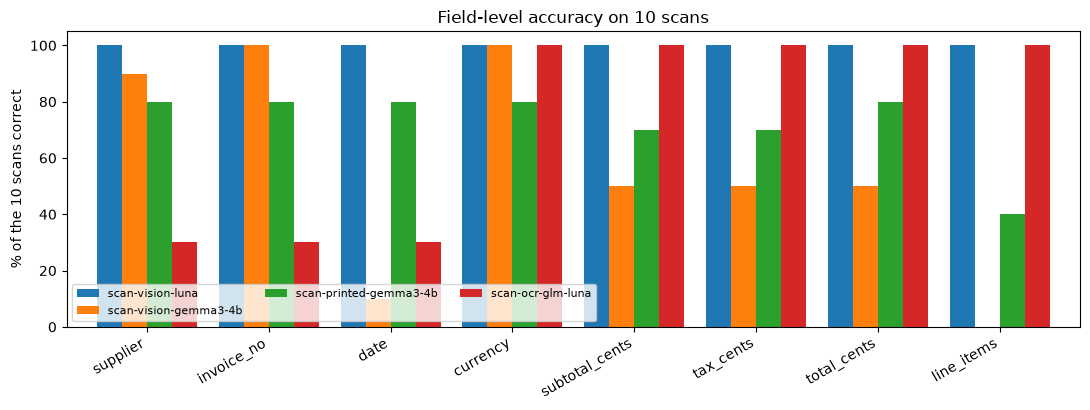

In [13]:
show = ["scan-vision-luna", "scan-vision-gemma3-4b", "scan-printed-gemma3-4b", "scan-ocr-glm-luna"]
acc = scan_table.loc[show, list(SCORE_FIELDS)].astype(float)
fig, ax = plt.subplots(figsize=(11, 4.2))
acc.T.plot.bar(ax=ax, width=0.82)
ax.set_ylabel("% of the 10 scans correct"); ax.set_ylim(0, 105)
ax.set_title("Field-level accuracy on 10 scans")
ax.legend(fontsize=8, ncol=3, loc="lower left"); plt.xticks(rotation=30, ha="right")
fig.tight_layout(); fig.savefig(IMAGES / "08-field-accuracy.png", dpi=110, facecolor="white")

### Escalation: fresh read or show the weak answer?

When the small model fails the rules, the strong model gets a second look. Two ways: show it the
weak answer and the broken rules (a *repair* conversation), or let it read the page from scratch.
Both saved runs use Luna on the same 10 scans; "with context" starts from gemma3:4b's answers.

In [14]:
esc = runs(["scan-vision-luna", "scan-escalate-context-luna"])
print(table(esc)[["n", "supplier", "all_correct", "caught", "silent_wrong", "usd_per_1k"]].to_string())
print("\n== scan-escalate-context-luna"); print("\n".join(mistakes("scan-escalate-context-luna")))
_, gemma = load_run(RESULTS / "scan-vision-gemma3-4b.json")
print("gemma3:4b had read the supplier as:", repr(gemma["scan-09.png"].invoice.supplier))

                             n  supplier  all_correct  caught  silent_wrong  usd_per_1k
scan-vision-luna            10     100.0        100.0     0.0           0.0        0.59
scan-escalate-context-luna  10      90.0         90.0     0.0           1.0        0.69

== scan-escalate-context-luna
scan-09.png [SILENT]
    supplier: 'Kettleley Homeware Ltd' (truth 'Kettleby Homeware Ltd')
gemma3:4b had read the supplier as: 'Kettleley Homeware Ltd'


### How many pixels does the page need?

Image tokens cost money. We downscale the scans before sending them to Luna.

In [15]:
SWEEP = {1754: "scan-vision-luna", 1200: "scan-vision-luna-1200px", 900: "scan-vision-luna-900px",
         700: "scan-vision-luna-700px", 500: "scan-vision-luna-500px"}
sweep_runs = runs(SWEEP.values())
rows = []
for px, name in SWEEP.items():
    _, res = sweep_runs[name]
    s = summarize(res)
    rows.append({"longest side px": px, "prompt tokens/page": res[0].extraction.prompt_tokens,
                 "all_correct %": s["all_correct"], "caught": int(s["caught"]),
                 "silent_wrong": int(s["silent_wrong"]), "usd_per_1k": round(s["usd_per_1k"], 3)})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))
for n in ["scan-vision-luna-700px", "scan-vision-luna-500px"]:
    print(f"\n== {n}"); print("\n".join(mistakes(n)))

 longest side px  prompt tokens/page  all_correct %  caught  silent_wrong  usd_per_1k
            1754                3049          100.0       0             0       0.591
            1200                1706          100.0       0             0       0.490
             900                1171          100.0       0             0       0.421
             700                 897           90.0       0             1       0.388
             500                 705           60.0       1             3       0.562

== scan-vision-luna-700px
scan-09.png [SILENT]
    line got ('KH-3919', 5, 241)
    line missed ('KH-5319', 5, 241)

== scan-vision-luna-500px
scan-02.png [SILENT]
    line got ('NV-3753', 2, 691)
    line missed ('NV-8065', 2, 691)
scan-05.png [SILENT]
    line got ('HL-3829', 1, 217)
    line missed ('HL-3289', 1, 217)
scan-06.png [SILENT]
    line got ('CF-4831', 36, 410)
    line missed ('CF-4871', 36, 410)
scan-07.png [caught: line_sum]
    line got ('TO-2655', 5, 339)
    

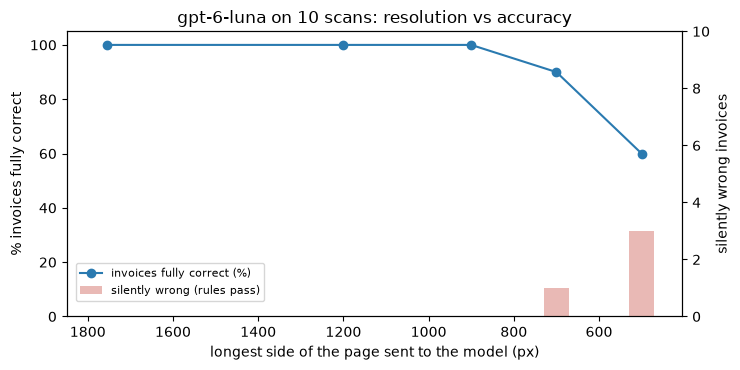

In [16]:
fig, ax1 = plt.subplots(figsize=(7.5, 3.8))
ax1.plot(sweep["longest side px"], sweep["all_correct %"], "o-", color="#2a7ab0", label="invoices fully correct (%)")
ax1.set_xlabel("longest side of the page sent to the model (px)"); ax1.set_ylabel("% invoices fully correct")
ax1.set_ylim(0, 105); ax1.invert_xaxis()
ax2 = ax1.twinx()
ax2.bar(sweep["longest side px"], sweep["silent_wrong"], width=60, alpha=0.35, color="#c0392b",
        label="silently wrong (rules pass)")
ax2.set_ylabel("silently wrong invoices"); ax2.set_ylim(0, 10)
ax1.set_title("gpt-6-luna on 10 scans: resolution vs accuracy")
fig.legend(loc="lower left", fontsize=8, bbox_to_anchor=(0.1, 0.18))
fig.tight_layout(); fig.savefig(IMAGES / "08-resolution.png", dpi=110, facecolor="white")

## Validation: what the rules catch and what they can't

In [17]:
everything = {**text_runs, **scan_runs, **{n: sweep_runs[n] for n in list(SWEEP.values())[1:]}}
buckets = pd.DataFrame({n: {"files": len(res),
                            "correct": sum(r.correct for r in res),
                            "caught": sum(not r.correct and r.flagged for r in res),
                            "silent_wrong": sum(not r.correct and not r.flagged for r in res),
                            "false_alarm": sum(r.correct and r.flagged for r in res)}
                        for n, (_, res) in everything.items()}).T
wrong = buckets.caught.sum() + buckets.silent_wrong.sum()
print(f"wrong invoices across all runs: {wrong}; caught by the rules: {buckets.caught.sum()} "
      f"({100 * buckets.caught.sum() / wrong:.1f}%); false alarms: {buckets.false_alarm.sum()}")
silent_fields = pd.Series([f for _, (_, res) in everything.items() for r in res
                           if not r.correct and not r.flagged
                           for f in SCORE_FIELDS if r.score[f] < 1]).value_counts()
print("fields wrong in the silent cases:", silent_fields.to_dict())
buckets

wrong invoices across all runs: 91; caught by the rules: 84 (92.3%); false alarms: 0
fields wrong in the silent cases: {'line_items': 7, 'invoice_no': 2}


,files,correct,caught,silent_wrong,false_alarm
text-naive-luna,50,50,0,0,0
text-v1-luna,50,50,0,0,0
text-v1-haiku,50,50,0,0,0
text-v1-qwen3-8b,50,39,11,0,0
text-printed-qwen3-8b,50,21,26,3,0
scan-vision-luna,10,10,0,0,0
scan-vision-sonnet,10,10,0,0,0
scan-vision-gemma3-4b,10,0,10,0,0
scan-ocr-glm-luna,10,3,7,0,0
scan-printed-luna,10,10,0,0,0


## The pipeline end to end

Route → extract → validate → repair → escalate → book it, or send it to `ch08_invoice_review`.

**hosted (live)**: Luna for text and vision (scans downscaled to 1200 px), Sonnet as the escalation
model, all 60 files.

In [18]:
FILES = sorted((DATA / "pdf").glob("*.pdf")) + sorted((DATA / "scans").glob("*.png"))
HOSTED = dict(text=ModelSpec(client, LUNA, max_side=1200),  # images downscaled, see the sweep
              strong=ModelSpec(client, settings.llm_model_strong))

def describe(outs):
    return pd.DataFrame([{
        "file": o.file, "method": o.method, "status": o.status,
        "stages": "+".join(a.stage for a in o.attempts),
        "correct": o.invoice is not None and score_invoice(o.invoice, TRUTH[o.file])["all"] == 1.0,
        "usd": o.cost_usd, "s": o.latency_s,
        "first_try_rules": ",".join(v.rule for v in o.attempts[0].violations) if o.attempts else "",
        "reasons": "; ".join(v.rule for v in o.reasons)} for o in outs])

def pipeline_summary(d):
    acc = d.status == "accepted"
    return {"files": len(d), "accepted": acc.sum(), "accepted_correct": (acc & d.correct).sum(),
            "accepted_WRONG": (acc & ~d.correct).sum(), "review": (~acc).sum(),
            "first_try_ok": (d.stages == "first").sum(),
            "fixed_by_repair": (acc & (d.stages == "first+repair")).sum(),
            "fixed_by_escalation": (acc & d.stages.str.endswith("escalate")).sum(),
            "usd_total": round(d.usd.sum(), 4), "usd_per_1k": round(1000 * d.usd.mean(), 3),
            "p50_s": round(d.s.median(), 1), "p95_s": round(d.s.quantile(0.95), 1)}

t0 = time.perf_counter()
with ThreadPoolExecutor(8) as pool:
    hosted_outs = list(pool.map(lambda p: process_file(p, **HOSTED), FILES))
print(f"hosted pipeline: {len(FILES)} files in {time.perf_counter() - t0:.0f} s wall")
hosted = describe(hosted_outs)
pipe = {"hosted (live)": hosted}

hosted pipeline: 60 files in 50 s wall


**local-first (saved run, if present)**: qwen3:8b for text, gemma3:4b for scans, both with
copy-then-convert, Luna as the escalation model (`eval/run_pipeline.py local-first-printed`).

In [19]:
p = RESULTS / "pipeline-local-first-printed-scans.json"
if p.exists():
    meta, local_outs = load_outcomes(p)
    print(meta)
    pipe["local-first, scans"] = describe(local_outs)
pd.DataFrame({n: pipeline_summary(d) for n, d in pipe.items()}).T

{'config': 'local-first-printed', 'files': 'scans', 'note': '', 'models': {'text': 'qwen3:8b', 'vision': 'gemma3:4b', 'strong': 'openai/gpt-6-luna'}, 'wall_s': 70.0, 'run_at': '2026-11-09T15:13:04'}


,files,accepted,accepted_correct,accepted_WRONG,review,first_try_ok,fixed_by_repair,fixed_by_escalation,usd_total,usd_per_1k,p50_s,p95_s
hosted (live),60.0,60.0,60.0,0.0,0.0,60.0,0.0,0.0,0.0202,0.336,5.0,13.0
"local-first, scans",10.0,10.0,10.0,0.0,0.0,2.0,2.0,6.0,0.0042,0.418,14.6,26.0


In [20]:
for n, d in pipe.items():
    x = d[(d.stages != "first") | (d.status != "accepted") | ~d.correct]
    print(f"--- {n}: {len(x)} files needed more than one try, or were wrong")
    print(x.drop(columns=["usd"]).round(1).to_string(index=False))

--- hosted (live): 0 files needed more than one try, or were wrong
Empty DataFrame
Columns: [file, method, status, stages, correct, s, first_try_rules, reasons]
Index: []
--- local-first, scans: 8 files needed more than one try, or were wrong
       file method   status                stages  correct    s    first_try_rules reasons
scan-02.png vision accepted first+repair+escalate     True 20.9           line_sum        
scan-03.png vision accepted first+repair+escalate     True 14.5           line_sum        
scan-04.png vision accepted first+repair+escalate     True 16.1           line_sum        
scan-05.png vision accepted          first+repair     True  7.8 line_sum,total_sum        
scan-07.png vision accepted first+repair+escalate     True 30.1        parse_error        
scan-08.png vision accepted first+repair+escalate     True 18.2           line_sum        
scan-09.png vision accepted first+repair+escalate     True 14.7        parse_error        
scan-10.png vision accepted  

### Booking into Postgres

We book the hosted run: PDFs first, then scans. Every scan is a copy of an invoice that also
arrived as a PDF, so the unique key `(supplier, invoice_no)` should send all 10 to review.

In [21]:
with connect() as conn:
    setup_tables(conn, reset=True)
    statuses = [record(conn, o) for o in hosted_outs]
    booked = conn.execute("SELECT count(*), count(DISTINCT currency) FROM ch08_invoices").fetchone()
    by_cur = conn.execute("SELECT currency, count(*), sum(total_cents) FROM ch08_invoices "
                          "GROUP BY currency ORDER BY currency").fetchall()
    review = conn.execute("SELECT id, source_file, method, rules, left(reason, 80) "
                          "FROM ch08_invoice_review ORDER BY id").fetchall()
print(f"booked: {booked[0]} invoices")
for cur, n, total in by_cur:
    print(f"  {cur}: {n} invoices, {total / 100:,.2f}")
print(f"review queue: {len(review)} rows")
for row in review:
    print(" ", row)

booked: 50 invoices
  EUR: 16 invoices, 37,189.71
  GBP: 8 invoices, 27,813.02
  USD: 26 invoices, 50,466.47
review queue: 10 rows
  (1, 'scan-01.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: Harbor Lane Packaging Inc. / B-29425 is already booked')
  (2, 'scan-02.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: Nordlicht Verpackung GmbH / RE-2026-1475 is already booked')
  (3, 'scan-03.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: Redwood Parcel Systems / T-96094 is already booked')
  (4, 'scan-04.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: Summit Ridge Outdoor Supply / A-27061 is already booked')
  (5, 'scan-05.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: Harbor Lane Packaging Inc. / K-82519 is already booked')
  (6, 'scan-06.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: Cobalt & Finch Hardware / INV-2026-08597 is already booked')
  (7, 'scan-07.png', 'vision', ['duplicate_invoice'], 'duplicate_invoice: This

## Cost summary

In [22]:
cost = pd.concat([text_table, scan_table])[["model", "n", "all_correct", "p50_s", "usd_per_1k", "note"]]
cost

,model,n,all_correct,p50_s,usd_per_1k,note
text-naive-luna,openai/gpt-6-luna,50,100.0,3.96,0.28,
text-v1-luna,openai/gpt-6-luna,50,100.0,4.04,0.31,
text-v1-haiku,anthropic/claude-haiku-5.5,50,100.0,3.04,0.56,
text-v1-qwen3-8b,qwen3:8b,50,78.0,4.10,0.00,
text-printed-qwen3-8b,qwen3:8b,50,42.0,4.20,0.00,
scan-vision-luna,openai/gpt-6-luna,10,100.0,10.00,0.59,
scan-vision-sonnet,anthropic/claude-sonnet-5.5,10,100.0,6.35,11.53,
scan-vision-gemma3-4b,gemma3:4b,10,0.0,5.59,0.00,
scan-ocr-glm-luna,openai/gpt-6-luna,10,30.0,5.37,0.25,
scan-printed-luna,openai/gpt-6-luna,10,100.0,9.08,0.64,
